<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/gauge_theory/gauge_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Gauge Theory* — `gauge_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Gauge Theory Ch 3 Figures — Colab Notebook
**Gauge Theory · Chapter 3: Anomalies**

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §3.1   | Chiral anomaly in 2D — spectral flow, chirality production |
| fig02  | §3.2.3 | Triangle diagram topology and anomaly coefficient |
| fig03  | §3.3   | Index theorem — Dirac spectrum, spectral flow |
| fig04  | §3.4.4 | SM anomaly cancellation — bar chart per fermion |
| fig05  | §3.5   | 't Hooft anomaly matching, phase diagram, $\theta=\pi$ transition |

## 수정 및 개선 사항 요약

| 그림 | 패널 | 분류 | 문제 | 수정 내용 |
|------|------|------|------|-----------|
| 전체 | Setup | **오류** | JSON 파싱 불가: Cell 4 `\dot`, `\frac`, `\pi` 가 단일 백슬래시 → invalid JSON escape | `\\dot`, `\\frac`, `\\pi` 로 수정 |
| fig02 | Left | **오류** | `arrowprops=dict(arrowstyle='<-', ..., arrowstyle='->', ...)` — keyword 중복 SyntaxError | 중복 `annotate` 호출 제거 |
| fig04 | Middle | **오류** | `contrib_d = Y × Nc`: [SU(2)]²U(1)_Y 공식에서 $T(R)=1/2$ (SU(2) fundamental) 누락. ylabel도 불완전 | `contrib_d = Y × 0.5 × Nc`, ylabel에 $T(R)$ 명시 |
| fig01–05 | 전체 | **경고** | `'$\\lambda=0$'` 등 non-raw string 내 LaTeX 이스케이프 → SyntaxWarning | `r'...'` prefix 추가 |
| fig04 | Left | **시인성** | 음수 막대 라벨이 바깥쪽으로 겹침 | 큰 막대: 안쪽 white/bold; 작은 막대: 바깥쪽 |
| fig03 | Left | **시인성** | k=-1 anti-instanton 설명 없음 | 주석에 k<0 경우(n₋=|k|) 설명 추가 |
| fig01 | Left | **시인성** | 오른쪽/왼쪽 모드의 채움 변화 설명 불명확 | '(filling increases/decreases)' 라벨 추가 |

**시인성 공통 개선**: minor tick 활성화, `tight_layout` 여백 증가


## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch, Rectangle
from matplotlib.lines import Line2D
import os

BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
AMBER  = '#e8a838'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#ffb347'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMBER, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
    'xtick.major.size': 4, 'ytick.major.size': 4,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete.')

Setup complete.


---
## fig01 · Chiral Anomaly in 2D — Spectral Flow (§3.1)

**Left**: Dirac sea of right- and left-movers; electric field shifts levels  
**Middle**: Rate of chirality production $\dot{N}_R - \dot{N}_L$ vs $E$  
**Right**: Axial charge $Q_5(t)$ growing linearly with applied field

  saved -> figures/ch03/fig01_chiral_anomaly_2d.png


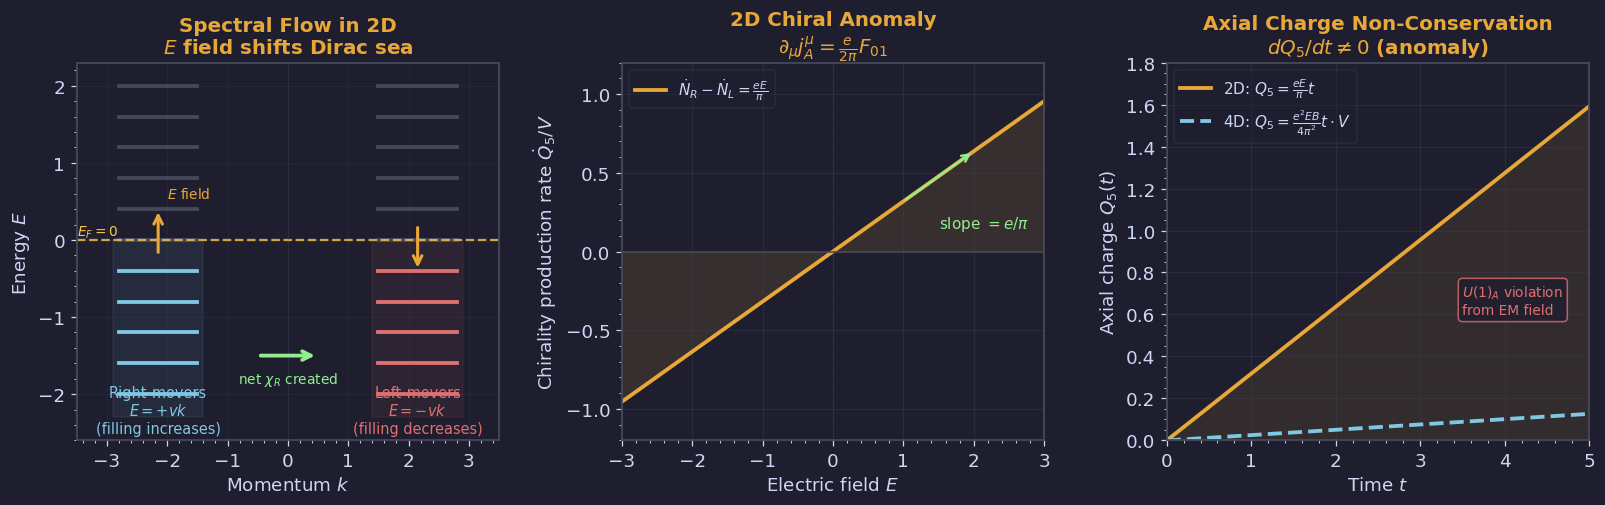

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Dirac sea spectral flow ─────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

# Draw energy levels for right-movers (R) and left-movers (L)
k_vals = np.arange(-5, 6)
E_threshold = 0.0

# Right-movers: E = +k (dispersion), left-movers: E = -k
# At E=0 (Fermi level): filled below

# Spectral flow: E field shifts all k-levels
# Right-movers: k→k+eEt → levels shift UP
# Left-movers: k→k+eEt → E=-vk shifts DOWN
for k in k_vals:
    E_R = k * 0.4   # right-mover dispersion E = vk
    E_L = -k * 0.4  # left-mover dispersion E = -vk
    col_R = BLUE if E_R < 0 else EDGE
    col_L = RED if E_L < 0 else EDGE
    ax.plot([-2.8, -1.5], [E_R, E_R], color=col_R, lw=2.5)
    ax.plot([+1.5, +2.8], [E_L, E_L], color=col_L, lw=2.5)

# Arrows showing shift under E field
ax.annotate('', xy=(-2.15, 0.4), xytext=(-2.15, -0.2),
            arrowprops=dict(arrowstyle='->', color=AMBER, lw=2, mutation_scale=14))
ax.text(-2.0, 0.55, r'$E$ field', fontsize=9, color=AMBER)
ax.annotate('', xy=(2.15, -0.4), xytext=(2.15, 0.2),
            arrowprops=dict(arrowstyle='->', color=AMBER, lw=2, mutation_scale=14))

# Fermi level
ax.axhline(0, color=YELLOW, lw=1.5, ls='--', alpha=0.8)
ax.text(-3.5, 0.05, r'$E_F=0$', fontsize=9, color=YELLOW)

# Labels
ax.text(-2.15, -2.5, 'Right-movers\n$E=+vk$\n(filling increases)', ha='center', fontsize=9.5, color=BLUE)
ax.text(+2.15, -2.5, 'Left-movers\n$E=-vk$\n(filling decreases)', ha='center', fontsize=9.5, color=RED)

# Filled = occupied markers
ax.fill_betweenx([-2.3, 0], -2.9, -1.4, color=BLUE, alpha=0.08)
ax.fill_betweenx([-2.3, 0],  1.4,  2.9, color=RED, alpha=0.08)

# Net chirality arrow
ax.annotate('', xy=(0.5, -1.5), xytext=(-0.5, -1.5),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.5, mutation_scale=14))
ax.text(0, -1.85, r'net $\chi_R$ created', ha='center', fontsize=9, color=GREEN)

ax.set_xlim(-3.5, 3.5); ax.set_ylim(-2.6, 2.3)
ax.set_xlabel(r'Momentum $k$')
ax.set_ylabel(r'Energy $E$')
ax.set_title('Spectral Flow in 2D\n'+r'$E$ field shifts Dirac sea', color=AMBER)
ax.axvline(0, color=EDGE, lw=0.8, ls=':', alpha=0.5)
ax.grid(True, alpha=0.2)

# ── Middle: chirality production rate vs E ────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

E_field = np.linspace(-3, 3, 200)
chiral_rate = E_field / np.pi   # d(N_R - N_L)/dt = eE/pi in 2D

ax2.plot(E_field, chiral_rate, color=AMBER, lw=2.5,
         label=r'$\dot{N}_R - \dot{N}_L = \frac{eE}{\pi}$')
ax2.fill_between(E_field, 0, chiral_rate, color=AMBER, alpha=0.12)

ax2.axhline(0, color=EDGE, lw=1)
ax2.axvline(0, color=EDGE, lw=0.8, ls=':', alpha=0.6)

# Slope annotation
ax2.annotate('', xy=(2, 2/np.pi), xytext=(1, 1/np.pi),
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.5))
ax2.text(1.5, 0.15, r'slope $= e/\pi$', fontsize=10, color=GREEN)

ax2.set_xlabel(r'Electric field $E$')
ax2.set_ylabel(r'Chirality production rate $\dot{Q}_5/V$')
ax2.set_title('2D Chiral Anomaly\n'+r'$\partial_\mu j_A^\mu = \frac{e}{2\pi}F_{01}$', color=AMBER)
ax2.legend(fontsize=10, labelcolor=FG)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(-3, 3); ax2.set_ylim(-1.2, 1.2)

# ── Right: axial charge Q5(t) growing with E ──────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

t_arr = np.linspace(0, 5, 300)

# Q5(t) = (e^2/4pi^2) * E*B * t (in 4D analogue; in 2D: eE/pi * t)
E_0 = 1.0
Q5_2d = E_0 / np.pi * t_arr
Q5_4d = E_0**2 / (4*np.pi**2) * t_arr   # E*B=E^2 for parallel fields

ax3.plot(t_arr, Q5_2d, color=AMBER, lw=2.5, label=r'2D: $Q_5 = \frac{eE}{\pi}t$')
ax3.plot(t_arr, Q5_4d, color=BLUE,  lw=2.5, ls='--',
         label=r'4D: $Q_5 = \frac{e^2 EB}{4\pi^2}t\cdot V$')

ax3.fill_between(t_arr, 0, Q5_2d, color=AMBER, alpha=0.1)

# Annotation: violation of axial symmetry
ax3.text(3.5, 0.6,
         r'$U(1)_A$ violation'+"\nfrom EM field",
         fontsize=9, color=RED,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=RED, alpha=0.8))

ax3.set_xlabel(r'Time $t$')
ax3.set_ylabel(r'Axial charge $Q_5(t)$')
ax3.set_title('Axial Charge Non-Conservation\n'+r'$dQ_5/dt \neq 0$ (anomaly)', color=AMBER)
ax3.legend(fontsize=10, labelcolor=FG)
ax3.grid(True, alpha=0.3)
ax3.set_xlim(0, 5); ax3.set_ylim(0, 1.8)

plt.tight_layout(pad=1.8)
save('fig01_chiral_anomaly_2d.png', fig)

---
## fig02 · Triangle Diagram & Anomaly Coefficient (§3.2.3)

**Left**: Triangle diagram schematic (axial + two vector vertices)  
**Middle**: Two orientations of fermion loop that must be summed  
**Right**: Anomaly coefficient $\sum Q^3$ for different charge assignments

  saved -> figures/ch03/fig02_triangle_diagram.png


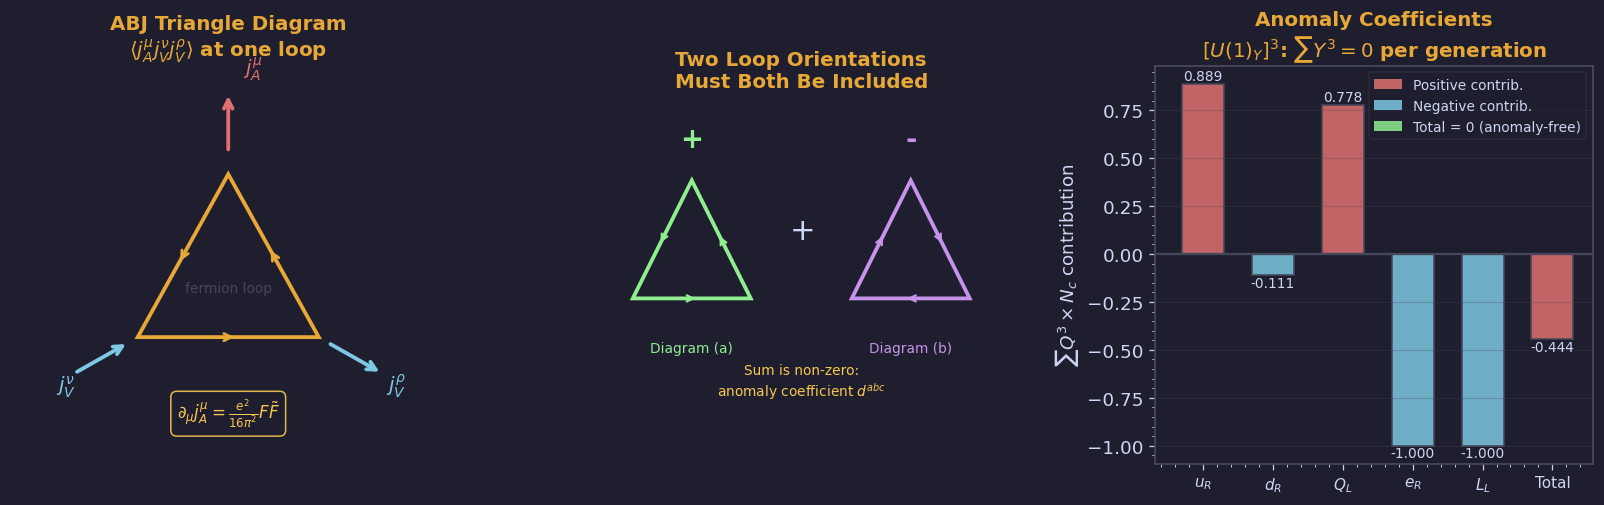

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Triangle diagram schematic ──────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')
ax.axis('off')

# Triangle vertices
h = np.sqrt(3)/2
v1 = np.array([0.0,  0.6])   # top (axial vertex)
v2 = np.array([-0.5, -0.3])  # bottom-left (vector 1)
v3 = np.array([+0.5, -0.3])  # bottom-right (vector 2)

# Draw triangle (fermion loop)
triangle = plt.Polygon([v1, v2, v3], fill=False, edgecolor=AMBER, lw=2.5)
ax.add_patch(triangle)

# Arrows on triangle edges (fermion propagators)
for start, end in [(v1, v2), (v2, v3), (v3, v1)]:
    mid = (start + end) / 2
    direction = end - start
    direction /= np.linalg.norm(direction)
    ax.annotate('', xy=mid + 0.05*direction, xytext=mid - 0.05*direction,
                arrowprops=dict(arrowstyle='->', color=AMBER, lw=1.8, mutation_scale=12))

# External legs
# Axial at top
ax.annotate('', xy=v1+[0,0.45], xytext=v1+[0,0.12],
            arrowprops=dict(arrowstyle='->', color=RED, lw=2.5, mutation_scale=14))
ax.text(v1[0]+0.08, v1[1]+0.55, r'$j^\mu_A$', color=RED, fontsize=13, fontweight='bold')

# Vector legs
ext_L = v2 + np.array([-0.35, -0.2])
ax.annotate('', xy=v2-[0.05, 0.03], xytext=ext_L,
            arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5, mutation_scale=14))
ax.text(ext_L[0]-0.1, ext_L[1]-0.1, r'$j^\nu_V$', color=BLUE, fontsize=13, fontweight='bold')

ext_R = v3 + np.array([+0.35, -0.2])
ax.annotate('', xy=v3+[0.05,-0.03], xytext=ext_R,
            arrowprops=dict(arrowstyle='<-', color=BLUE, lw=2.5, mutation_scale=14))
ax.text(ext_R[0]+0.02, ext_R[1]-0.1, r'$j^\rho_V$', color=BLUE, fontsize=13, fontweight='bold')

# Momentum labels
ax.text(0, -0.05, 'fermion loop', ha='center', fontsize=9, color=EDGE)

# ABJ result
ax.text(0, -0.75,
        r'$\partial_\mu j^\mu_A = \frac{e^2}{16\pi^2}F\tilde{F}$',
        ha='center', fontsize=11, color=YELLOW,
        bbox=dict(boxstyle='round,pad=0.35', facecolor=BG, edgecolor=YELLOW, alpha=0.9))

ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.0, 1.2)
ax.set_title('ABJ Triangle Diagram\n'+r'$\langle j_A^\mu j_V^\nu j_V^\rho\rangle$ at one loop', color=AMBER)

# ── Middle: Two fermion loop orientations ─────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_aspect('equal')
ax2.axis('off')

# Two triangles side by side
offset = [-0.65, 0.65]
colors = [GREEN, PURPLE]
labels = ['Diagram (a)', 'Diagram (b)']
signs  = ['+', '-']
for i, (xoff, col, lbl, sgn) in enumerate(zip(offset, colors, labels, signs)):
    v1_ = np.array([xoff,  0.5])
    v2_ = np.array([xoff-0.35, -0.2])
    v3_ = np.array([xoff+0.35, -0.2])
    tri = plt.Polygon([v1_, v2_, v3_], fill=False, edgecolor=col, lw=2.5)
    ax2.add_patch(tri)
    # Arrow directions reversed for second diagram
    edges = [(v1_, v2_), (v2_, v3_), (v3_, v1_)] if i==0 else [(v2_, v1_), (v3_, v2_), (v1_, v3_)]
    for start, end in edges:
        mid = (start + end) / 2
        direction = end - start
        direction /= np.linalg.norm(direction)
        ax2.annotate('', xy=mid+0.04*direction, xytext=mid-0.04*direction,
                    arrowprops=dict(arrowstyle='->', color=col, lw=1.5, mutation_scale=10))
    ax2.text(xoff, -0.52, lbl, ha='center', fontsize=9, color=col)
    ax2.text(xoff, 0.7, sgn, ha='center', fontsize=18, color=col, fontweight='bold')

# Sum
ax2.text(0, 0.15, r'$+$', ha='center', fontsize=20, color=FG)
ax2.text(0, -0.78,
         'Sum is non-zero:\nanomaly coefficient $d^{abc}$',
         ha='center', fontsize=9, color=YELLOW)

ax2.set_xlim(-1.3, 1.3); ax2.set_ylim(-1.0, 1.0)
ax2.set_title('Two Loop Orientations\nMust Both Be Included', color=AMBER)

# ── Right: Anomaly coefficient Q^3 ────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

# Show sum Q^3 for different fermion species
species = ['$u_R$', '$d_R$', '$Q_L$', '$e_R$', '$L_L$', 'Total']
Q_charges = [2/3, -1/3, [2/3,-1/3], -1, [0,-1], None]

# Per-species Q^3 contributions (Nc=3 for quarks)
contrib = [
    3*(2/3)**3,          # u_R
    3*(-1/3)**3,         # d_R
    3*((2/3)**3 + (-1/3)**3),  # Q_L doublet
    (-1)**3,             # e_R
    (0**3 + (-1)**3),    # L_L doublet
]
total = sum(contrib)
contrib_plot = contrib + [total]

bar_colors = [RED if c > 0 else BLUE for c in contrib]
bar_colors.append(GREEN if abs(total) < 0.01 else RED)

bars = ax3.bar(range(len(species)), contrib_plot, color=bar_colors,
               edgecolor=EDGE, linewidth=1.2, alpha=0.85, width=0.6)

ax3.axhline(0, color=EDGE, lw=1.5)

# Value labels on bars
for bar, val in zip(bars, contrib_plot):
    ypos = bar.get_height() + (0.02 if val >= 0 else -0.06)
    ax3.text(bar.get_x()+bar.get_width()/2, ypos,
             f'{val:.3f}', ha='center', fontsize=9, color=FG)

ax3.set_xticks(range(len(species)))
ax3.set_xticklabels(species, fontsize=10)
ax3.set_ylabel(r'$\sum Q^3 \times N_c$ contribution')
ax3.set_title('Anomaly Coefficients\n'+r'$[U(1)_Y]^3$: $\sum Y^3 = 0$ per generation', color=AMBER)
ax3.grid(True, axis='y', alpha=0.3)

ax3.bar(0, 0, color=RED,  label='Positive contrib.', alpha=0.85)
ax3.bar(0, 0, color=BLUE, label='Negative contrib.', alpha=0.85)
ax3.bar(0, 0, color=GREEN,label='Total = 0 (anomaly-free)', alpha=0.85)
ax3.legend(fontsize=9, labelcolor=FG)

plt.tight_layout(pad=1.8)
save('fig02_triangle_diagram.png', fig)

---
## fig03 · Index Theorem — Dirac Spectrum & Spectral Flow (§3.3)

**Left**: Dirac operator eigenvalue spectrum — zero modes and $\pm\lambda$ pairs  
**Middle**: Index $n_+ - n_-$ vs instanton number $k$ — integer-valued  
**Right**: Spectral flow in a $k=1$ background — one mode crosses zero

  saved -> figures/ch03/fig03_index_theorem.png


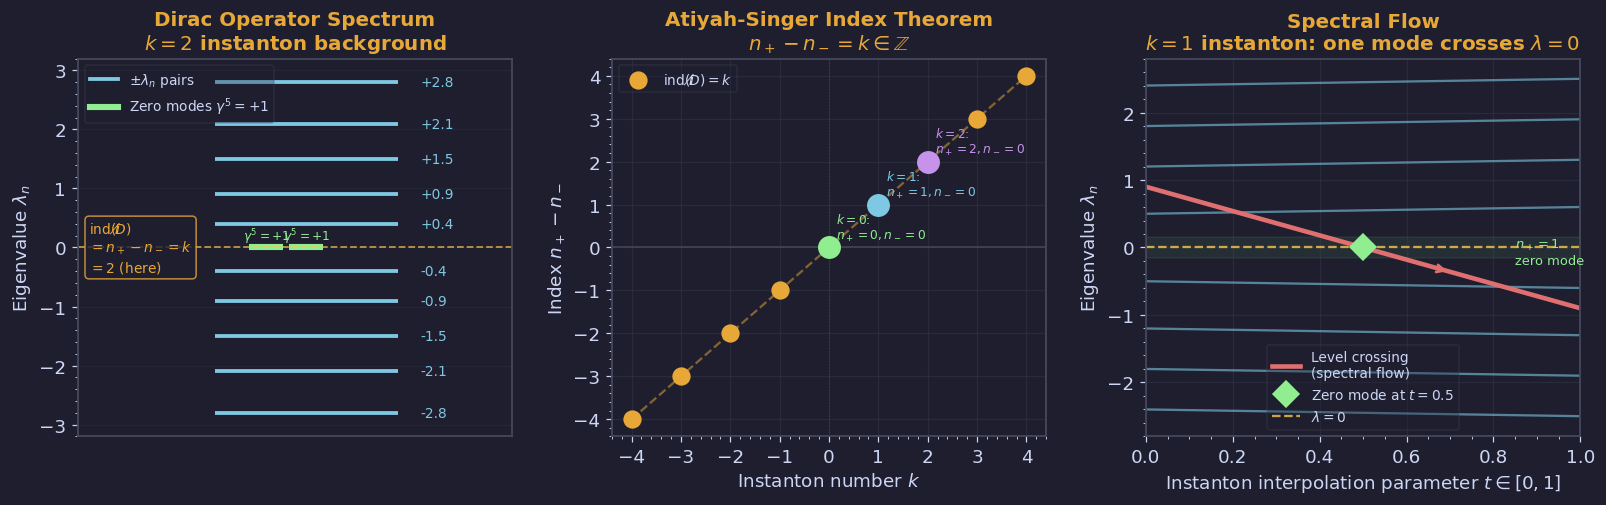

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Dirac spectrum ───────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

# Non-zero eigenvalue pairs (+lambda, -lambda)
lambdas_pos = [0.4, 0.9, 1.5, 2.1, 2.8]
# Zero modes: n+ positive chirality, n- negative chirality
# k=2 instanton → n_+=2, n_-=0; k=-2 anti-instanton → n_+=0, n_-=2
n_plus = 2
n_minus = 0  # For k=2 instanton background

# Draw +/- pairs
for lam in lambdas_pos:
    ax.hlines(lam,  -0.8, 0.8, colors=BLUE, lw=2.5)
    ax.hlines(-lam, -0.8, 0.8, colors=BLUE, lw=2.5)
    ax.text(1.0, lam,  f'+{lam:.1f}', fontsize=9, color=BLUE, va='center')
    ax.text(1.0, -lam, f'-{lam:.1f}', fontsize=9, color=BLUE, va='center')

# Zero modes
for i in range(n_plus):
    xpos = -0.35 + i*0.35
    ax.hlines(0, xpos-0.15, xpos+0.15, colors=GREEN, lw=4)
    ax.text(xpos, 0.12, r'$\gamma^5=+1$', ha='center', fontsize=8, color=GREEN)

for i in range(n_minus):
    xpos = 0.3 + i*0.35
    ax.hlines(0, xpos-0.15, xpos+0.15, colors=RED, lw=4)
    ax.text(xpos, -0.18, r'$\gamma^5=-1$', ha='center', fontsize=8, color=RED)

# Zero axis
ax.axhline(0, color=YELLOW, lw=1.2, ls='--', alpha=0.7)

# Braces and index label
ax.text(-1.9, 0.0,
        r'$\mathrm{ind}(i\not\!\!D)$'+"\n"+r'$= n_+ - n_- = k$'+"\n"+'$= 2$ (here)',
        fontsize=9, color=AMBER, va='center',
        bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=AMBER, alpha=0.8))

ax.set_xlim(-2.0, 1.8)
ax.set_ylim(-3.2, 3.2)
ax.set_xticks([])
ax.set_ylabel(r'Eigenvalue $\lambda_n$')
ax.set_title('Dirac Operator Spectrum\n'+r'$k=2$ instanton background', color=AMBER)

legend_elements = [
    Line2D([0],[0], color=BLUE,  lw=2.5, label=r'$\pm\lambda_n$ pairs'),
    Line2D([0],[0], color=GREEN, lw=4,   label=r'Zero modes $\gamma^5=+1$'),
]
ax.legend(handles=legend_elements, fontsize=9, labelcolor=FG, loc='upper left')
ax.grid(True, axis='y', alpha=0.2)

# ── Middle: Index vs instanton number ─────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

k_range = np.arange(-4, 5)
index_vals = k_range   # ind = k exactly

ax2.scatter(k_range, index_vals, color=AMBER, s=120, zorder=5,
            label=r'$\mathrm{ind}(i\not\!\!D) = k$')
ax2.plot(k_range, index_vals, color=AMBER, lw=1.5, ls='--', alpha=0.5)

# Highlight k=0,1,2
for k_hi, col in [(0, GREEN), (1, BLUE), (2, PURPLE)]:
    ax2.plot(k_hi, k_hi, 'o', color=col, ms=14, zorder=6)
    ax2.text(k_hi+0.15, k_hi+0.2,
             f'$k={k_hi}$:\n$n_+={max(k_hi,0)}, n_-={max(-k_hi,0)}$',
             fontsize=8, color=col)

ax2.axhline(0, color=EDGE, lw=1)
ax2.axvline(0, color=EDGE, lw=0.8, ls=':', alpha=0.6)
ax2.set_xlabel(r'Instanton number $k$')
ax2.set_ylabel(r'Index $n_+ - n_-$')
ax2.set_title('Atiyah-Singer Index Theorem\n'+r'$n_+ - n_- = k \in \mathbb{Z}$', color=AMBER)
ax2.set_xticks(k_range)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.grid(True, alpha=0.3)

# ── Right: Spectral flow ───────────────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

# As instanton is dialed from 0 to 1 (interpolation parameter t in [0,1]),
# one eigenvalue crosses from +lambda to 0 (zero mode) to -lambda?
# Actually: in spectral flow, one mode crosses lambda=0 from positive to negative
# (for anti-instanton) or from negative to positive (for instanton)

t_param = np.linspace(0, 1, 300)  # instanton parameter 0->1

# Several eigenvalues: most stay away from zero, one crosses
lam_stable = [0.5, 1.2, 1.8, 2.4, -0.5, -1.2, -1.8, -2.4]
for lam_s in lam_stable:
    # Slight drift
    drift = 0.1 * t_param * np.sign(lam_s)
    ax3.plot(t_param, lam_s + drift, color=BLUE, lw=1.5, alpha=0.6)

# The crossing mode: starts at +0.9 at t=0, crosses zero at t=0.5, goes to -0.9
lam_cross = 0.9 * (1 - 2*t_param)
ax3.plot(t_param, lam_cross, color=RED, lw=3, label='Level crossing\n(spectral flow)')

# Mark the crossing point
ax3.plot(0.5, 0, 'D', color=GREEN, ms=12, zorder=5, label='Zero mode at $t=0.5$')

# Reference line
ax3.axhline(0, color=YELLOW, lw=1.5, ls='--', alpha=0.8, label=r'$\lambda=0$')

# Arrows showing direction
ax3.annotate('', xy=(0.7, lam_cross[210]), xytext=(0.55, lam_cross[165]),
             arrowprops=dict(arrowstyle='->', color=RED, lw=1.8, mutation_scale=12))

ax3.fill_betweenx([-0.15, 0.15], 0, 1, color=GREEN, alpha=0.08)
ax3.text(0.85, -0.25, r'$n_+=1$'+"\n"+'zero mode', fontsize=8.5, color=GREEN)

ax3.set_xlabel(r'Instanton interpolation parameter $t\in[0,1]$')
ax3.set_ylabel(r'Eigenvalue $\lambda_n$')
ax3.set_title('Spectral Flow\n'+r'$k=1$ instanton: one mode crosses $\lambda=0$', color=AMBER)
ax3.set_xlim(0, 1); ax3.set_ylim(-2.8, 2.8)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, alpha=0.3)

plt.tight_layout(pad=1.8)
save('fig03_index_theorem.png', fig)

---
## fig04 · SM Anomaly Cancellation (§3.4.4)

**Left**: $[U(1)_Y]^3$ anomaly contributions per SM fermion  
**Middle**: $[SU(2)]^2 U(1)_Y$ contributions  
**Right**: Summary — all four anomaly conditions with total = 0

  saved -> figures/ch03/fig04_sm_anomaly.png


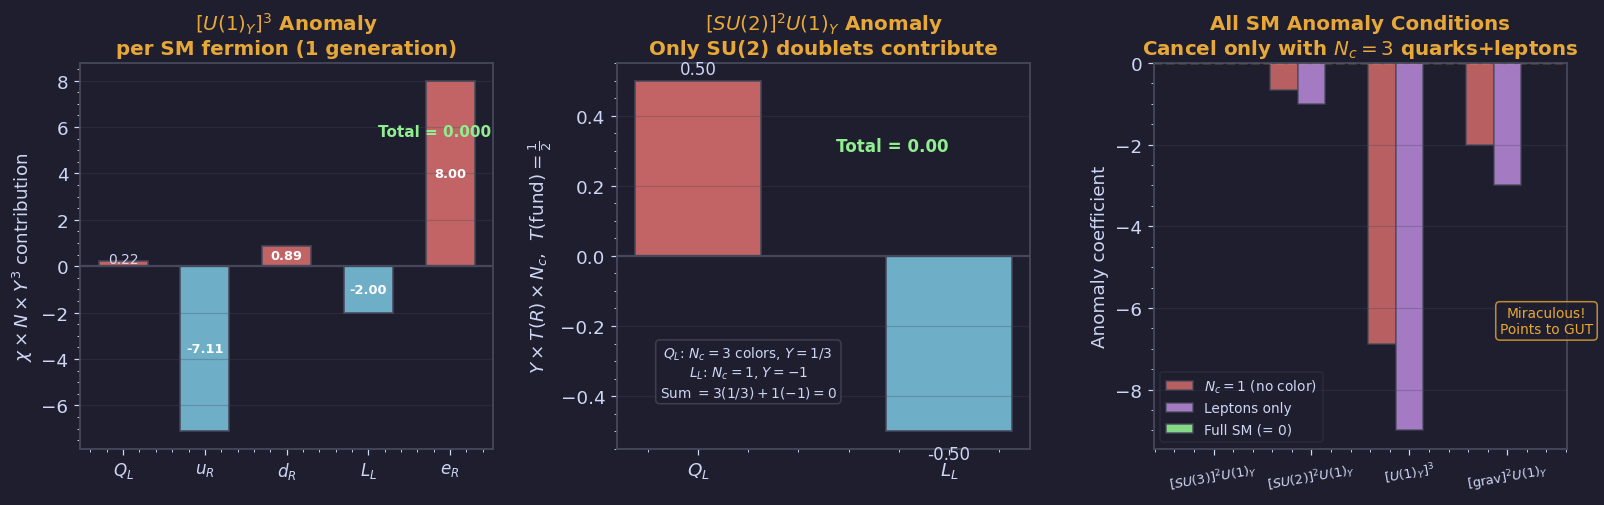

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: [U(1)_Y]^3 anomaly per fermion ──────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

# SM hypercharges Y (normalised so Q = T3 + Y/2)
# Field: (name, Y, multiplicity, chirality)
sm_fields = [
    (r'$Q_L$',  1/3,  3*2, 'L'),   # SU(2) doublet, Nc=3 -> 6 d.o.f.
    (r'$u_R$',  4/3,  3,   'R'),
    (r'$d_R$', -2/3,  3,   'R'),
    (r'$L_L$', -1,    2,   'L'),   # SU(2) doublet
    (r'$e_R$', -2,    1,   'R'),
]
# For [U(1)]^3: contribution = multiplicity * Y^3 * (sign for chirality: +L, -R)
# Actually standard: left-handed = +, right-handed = - (Weyl convention)
# [U(1)_Y]^3: sum Y^3 over left-handed - sum Y^3 over right-handed
names = [f[0] for f in sm_fields]
Y_vals = [f[1] for f in sm_fields]
mult   = [f[2] for f in sm_fields]
chir   = [+1 if f[3]=='L' else -1 for f in sm_fields]

contrib_Y3 = [ch * m * Y**3 for ch, m, Y in zip(chir, mult, Y_vals)]
total_Y3 = sum(contrib_Y3)

bar_cols = [RED if c > 0 else BLUE for c in contrib_Y3]
ax.bar(range(len(names)), contrib_Y3, color=bar_cols, edgecolor=EDGE, lw=1.2, alpha=0.85, width=0.6)

for i, val in enumerate(contrib_Y3):
    if abs(val) > 0.5:  # 막대가 충분히 크면 안쪽
        ypos = val * 0.5
        ax.text(i, ypos, f'{val:.2f}', ha='center', va='center',
                fontsize=8.5, color='white', fontweight='bold')
    else:  # 작은 막대: 바깥쪽
        ypos = val + (0.08 if val >= 0 else -0.15)
        ax.text(i, ypos, f'{val:.2f}', ha='center', va='center',
                fontsize=9, color=FG)

ax.axhline(0, color=EDGE, lw=1.5)
ax.text(len(names)-0.5, max(contrib_Y3)*0.7,
        f'Total = {total_Y3:.3f}',
        ha='right', fontsize=10, color=GREEN if abs(total_Y3)<0.01 else RED,
        fontweight='bold')

ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, fontsize=11)
ax.set_ylabel(r'$\chi \times N \times Y^3$ contribution')
ax.set_title(r'$[U(1)_Y]^3$ Anomaly'+"\nper SM fermion (1 generation)", color=AMBER)
ax.grid(True, axis='y', alpha=0.3)

# ── Middle: [SU(2)]^2 U(1)_Y ──────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

# Only SU(2) doublets contribute: Q_L (Y=1/3, Nc=3) and L_L (Y=-1, 1 species)
doublets = [(r'$Q_L$', 1/3, 3), (r'$L_L$', -1, 1)]
names_d  = [d[0] for d in doublets]
# FIX: 정확한 공식에는 T(R)=1/2 (SU(2) fundamental) 포함
contrib_d = [d[1]*0.5*d[2] for d in doublets]  # Y × T(R) × Nc
total_d   = sum(contrib_d)

bar_cols_d = [RED if c > 0 else BLUE for c in contrib_d]
bars_d = ax2.bar(range(len(names_d)), contrib_d, color=bar_cols_d,
                 edgecolor=EDGE, lw=1.2, alpha=0.85, width=0.5)

for i, val in enumerate(contrib_d):
    ax2.text(i, val + (0.02 if val >= 0 else -0.08), f'{val:.2f}',
             ha='center', fontsize=11, color=FG)

ax2.axhline(0, color=EDGE, lw=1.5)
ax2.text(1.0, max(abs(c) for c in contrib_d)*0.6,
         f'Total = {total_d:.2f}',
         ha='right', fontsize=11, color=GREEN if abs(total_d)<0.01 else RED,
         fontweight='bold')

ax2.set_xticks(range(len(names_d)))
ax2.set_xticklabels(names_d, fontsize=12)
ax2.set_ylabel(r'$Y \times T(R) \times N_c$,  $T(\text{fund})=\frac{1}{2}$')
ax2.set_title(r'$[SU(2)]^2 U(1)_Y$ Anomaly'+"\nOnly SU(2) doublets contribute", color=AMBER)
ax2.grid(True, axis='y', alpha=0.3)

# Note on Nc
ax2.text(0.2, -0.4,
         r'$Q_L$: $N_c=3$ colors, $Y=1/3$'+"\n"+r'$L_L$: $N_c=1$, $Y=-1$'+"\n"+r'Sum $= 3(1/3) + 1(-1) = 0$',
         ha='center', fontsize=9, color=FG,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=EDGE, alpha=0.8))

# ── Right: Summary table of all anomaly conditions ────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

conditions = [
    r'$[SU(3)]^2 U(1)_Y$',
    r'$[SU(2)]^2 U(1)_Y$',
    r'$[U(1)_Y]^3$',
    r'$[\mathrm{grav}]^2 U(1)_Y$',
]
# All are zero for SM
values_sm  = [0.0, 0.0, 0.0, 0.0]
# What they would be without quarks (leptons only)
values_lep = [0.0, -1.0, (-1)**3 + 0 + (-2)**3, -1+0-2]  # schematic
# What they would be without colour (Nc=1)
values_nc1 = [0.0, 1/3-1, (1/3)**3+(4/3)**3+(-2/3)**3+0+(-1)**3+(-2)**3, 1/3+4/3-2/3-1-2]

x_pos = np.arange(len(conditions))
width = 0.28

ax3.bar(x_pos - width, values_nc1, width, color=RED,    alpha=0.8, label=r'$N_c=1$ (no color)', edgecolor=EDGE)
ax3.bar(x_pos,         values_lep, width, color=PURPLE, alpha=0.8, label='Leptons only',         edgecolor=EDGE)
ax3.bar(x_pos + width, values_sm,  width, color=GREEN,  alpha=0.9, label='Full SM (= 0)',        edgecolor=EDGE)

ax3.axhline(0, color=YELLOW, lw=1.5, ls='--')
ax3.set_xticks(x_pos)
ax3.set_xticklabels(conditions, fontsize=8.5, rotation=10)
ax3.set_ylabel('Anomaly coefficient')
ax3.set_title('All SM Anomaly Conditions\n'+r'Cancel only with $N_c=3$ quarks+leptons', color=AMBER)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, axis='y', alpha=0.3)

# Annotation
ax3.text(3.4, ax3.get_ylim()[0]*0.7,
         'Miraculous!\nPoints to GUT',
         fontsize=9, color=AMBER, ha='center',
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=AMBER, alpha=0.8))

plt.tight_layout(pad=1.8)
save('fig04_sm_anomaly.png', fig)

---
## fig05 · 't Hooft Anomaly Matching & Phase Diagram (§3.5)

**Left**: UV anomaly (quarks) = IR anomaly (WZW pions) — matching diagram  
**Middle**: Phase diagram with 't Hooft anomaly constraint  
**Right**: $\theta$-dependence of vacuum energy and phase transition at $\theta=\pi$

  saved -> figures/ch03/fig05_thooft_matching.png


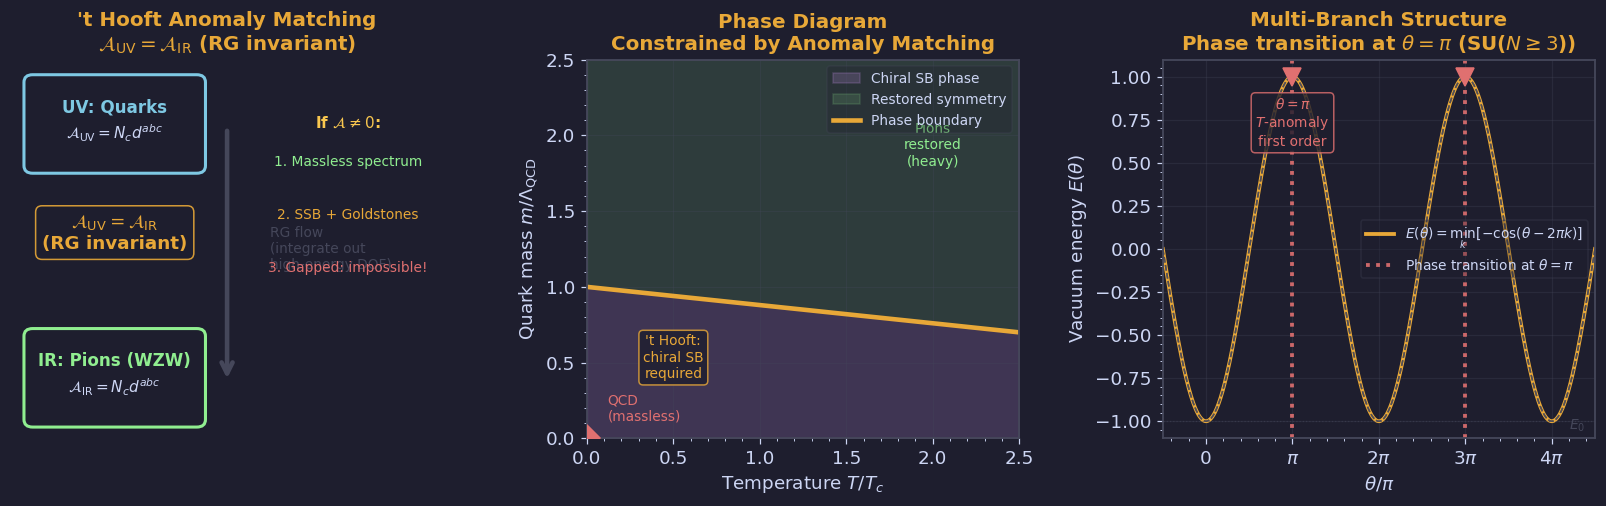

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: UV = IR anomaly matching schematic ───────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.axis('off')

# RG flow arrow
ax.annotate('', xy=(0.5, 0.15), xytext=(0.5, 0.82),
            arrowprops=dict(arrowstyle='->', color=EDGE, lw=3, mutation_scale=18),
            xycoords='axes fraction', textcoords='axes fraction')
ax.text(0.6, 0.5, 'RG flow\n(integrate out\nhigh-energy DOF)',
        fontsize=9, color=EDGE, transform=ax.transAxes, va='center')

# UV box
uv_box = FancyBboxPatch((0.05, 0.72), 0.38, 0.22,
                         boxstyle='round,pad=0.02', facecolor=BG,
                         edgecolor=BLUE, linewidth=2)
ax.add_patch(uv_box)
ax.text(0.24, 0.86, 'UV: Quarks', ha='center', fontsize=11,
        color=BLUE, fontweight='bold', transform=ax.transAxes)
ax.text(0.24, 0.79, r'$\mathcal{A}_{\rm UV} = N_c d^{abc}$',
        ha='center', fontsize=10, color=FG, transform=ax.transAxes)

# IR box
ir_box = FancyBboxPatch((0.05, 0.05), 0.38, 0.22,
                         boxstyle='round,pad=0.02', facecolor=BG,
                         edgecolor=GREEN, linewidth=2)
ax.add_patch(ir_box)
ax.text(0.24, 0.19, 'IR: Pions (WZW)', ha='center', fontsize=11,
        color=GREEN, fontweight='bold', transform=ax.transAxes)
ax.text(0.24, 0.12, r'$\mathcal{A}_{\rm IR} = N_c d^{abc}$',
        ha='center', fontsize=10, color=FG, transform=ax.transAxes)

# Equality
ax.text(0.24, 0.50,
        r"$\mathcal{A}_{\rm UV} = \mathcal{A}_{\rm IR}$"+"\n"+'(RG invariant)',
        ha='center', fontsize=12, color=AMBER, fontweight='bold',
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.35', facecolor=BG, edgecolor=AMBER, alpha=0.9))

# Possible IR fates
ax.text(0.78, 0.82, "If $\\mathcal{A}\\neq 0$:",
        ha='center', fontsize=10, color=YELLOW, fontweight='bold',
        transform=ax.transAxes)
for i, (txt, col) in enumerate([
    ('1. Massless spectrum', GREEN),
    ('2. SSB + Goldstones', AMBER),
    ('3. Gapped: impossible!', RED)
]):
    ax.text(0.78, 0.72 - i*0.14, txt,
            ha='center', fontsize=9, color=col, transform=ax.transAxes)

ax.set_title("'t Hooft Anomaly Matching\n"+r'$\mathcal{A}_{\rm UV}=\mathcal{A}_{\rm IR}$ (RG invariant)', color=AMBER)

# ── Middle: Phase diagram constrained by anomaly ───────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

# Axes: temperature T vs quark mass m
T = np.linspace(0, 2.5, 300)
m_vals = np.linspace(-0.5, 2.5, 300)
T_grid, m_grid = np.meshgrid(T, m_vals)

# Schematic: chiral symmetry broken for T < Tc(m=0), restored above
Tc = 1.0   # critical temperature at m=0
# Crossover region
crossover = Tc + 0.2*m_grid  # Tc increases with m

# Fill regions
ax2.fill_between(T, 0, Tc*(1-0.3*T/2.5),
                 color=PURPLE, alpha=0.2, label='Chiral SB phase')
ax2.fill_between(T, Tc*(1-0.3*T/2.5), 2.5,
                 color=GREEN, alpha=0.15, label='Restored symmetry')

# Phase boundary
T_boundary = np.linspace(0, 2.5, 100)
m_boundary = 1.0 * (1 - 0.3*T_boundary/2.5)
ax2.plot(T_boundary, m_boundary, color=AMBER, lw=3, label='Phase boundary')

# 't Hooft anomaly constraint annotation
ax2.text(0.5, 0.4,
         "'t Hooft:\nchiral SB\nrequired",
         ha='center', fontsize=9, color=AMBER,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=AMBER, alpha=0.8))
ax2.text(2.0, 1.8, 'Pions\nrestored\n(heavy)',
         ha='center', fontsize=9, color=GREEN)

# QCD point
ax2.plot(0, 0, 'D', color=RED, ms=12, zorder=5)
ax2.text(0.12, 0.12, 'QCD\n(massless)', fontsize=9, color=RED)

ax2.set_xlabel(r'Temperature $T/T_c$')
ax2.set_ylabel(r'Quark mass $m/\Lambda_{\rm QCD}$')
ax2.set_title('Phase Diagram\nConstrained by Anomaly Matching', color=AMBER)
ax2.legend(fontsize=9, labelcolor=FG, loc='upper right')
ax2.set_xlim(0, 2.5); ax2.set_ylim(0, 2.5)
ax2.grid(True, alpha=0.3)

# ── Right: theta-dependence and transition at theta=pi ────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

theta_arr = np.linspace(-0.5, 4.5, 1000) * np.pi

# Multi-branch vacuum energy: E_k(theta) = -cos(theta - 2pi k) (large N branches)
Nbranch = 4
theta_norm = theta_arr / np.pi

E_min = np.full_like(theta_norm, np.inf)
k_min = np.zeros_like(theta_norm, dtype=int)

for k in range(-Nbranch, Nbranch+1):
    E_k = -np.cos(theta_arr - 2*np.pi*k)
    mask = E_k < E_min
    E_min[mask] = E_k[mask]
    k_min[mask] = k

ax3.plot(theta_norm, E_min, color=AMBER, lw=2.5, label=r'$E(\theta) = \min_k[-\cos(\theta-2\pi k)]$')

# Individual branches
for k in range(-2, 3):
    E_branch = -np.cos(theta_arr - 2*np.pi*k)
    ax3.plot(theta_norm, E_branch, color=EDGE, lw=1, ls='--', alpha=0.4)

# First-order transition at theta = pi
ax3.axvline(1, color=RED, lw=2.5, ls=':', alpha=0.9, label=r'Phase transition at $\theta=\pi$')
ax3.axvline(3, color=RED, lw=2.5, ls=':', alpha=0.9)

# Annotation
ax3.text(1.0, 0.6,
         r"$\theta=\pi$"+"\n"+r"$T$-anomaly"+"\n"+"first order",
         ha='center', fontsize=9, color=RED,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=RED, alpha=0.8))

# Cusp at phase transition
ax3.plot(1, E_min[np.argmin(abs(theta_norm - 1))], 'v', color=RED, ms=12, zorder=5)
ax3.plot(3, E_min[np.argmin(abs(theta_norm - 3))], 'v', color=RED, ms=12, zorder=5)

ax3.axhline(-1, color=EDGE, lw=0.8, ls=':', alpha=0.5)
ax3.text(4.2, -1.05, r'$E_0$', fontsize=9, color=EDGE)

ax3.set_xlabel(r'$\theta/\pi$')
ax3.set_ylabel(r'Vacuum energy $E(\theta)$')
ax3.set_title(r'Multi-Branch Structure'+"\n"+r'Phase transition at $\theta=\pi$ (SU($N\geq 3$))', color=AMBER)
ax3.set_xticks([0,1,2,3,4])
ax3.set_xticklabels(['0', r'$\pi$', r'$2\pi$', r'$3\pi$', r'$4\pi$'])
ax3.set_xlim(-0.5, 4.5)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, alpha=0.3)

plt.tight_layout(pad=1.8)
save('fig05_thooft_matching.png', fig)

---
## Download figures

In [7]:
import shutil
from google.colab import files

shutil.make_archive('gauge_ch03_figures', 'zip', '.', 'figures')
files.download('gauge_ch03_figures.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Checklist

| File | Content | Status |
|------|---------|--------|
| `fig01_chiral_anomaly_2d.png` | Spectral flow / chirality rate / axial charge | ☐ |
| `fig02_triangle_diagram.png`  | Triangle diagram / loop orientations / $\sum Q^3$ | ☐ |
| `fig03_index_theorem.png`     | Dirac spectrum / index vs $k$ / spectral flow | ☐ |
| `fig04_sm_anomaly.png`        | $[U(1)_Y]^3$ / $[SU(2)]^2 U(1)_Y$ / all conditions | ☐ |
| `fig05_thooft_matching.png`   | UV=IR matching / phase diagram / $\theta=\pi$ transition | ☐ |